<a href="https://colab.research.google.com/github/kon7drat-illia/Machine_Learning_ML_2026/blob/main/%D0%9B%D0%A0_8_%D0%9C%D0%9D_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%9A%D0%BE%D0%BD%D0%B4%D1%80%D0%B0%D1%82%D0%B5%D0%BD%D0%BA%D0%BE_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
df_iris = pd.DataFrame(data=iris.data, columns=iris.feature_names)
print("--- 1.2. Перші 5 рядків датасету Iris ---")
print(df_iris.head())
print()

--- 1.2. Перші 5 рядків датасету Iris ---
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2



**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

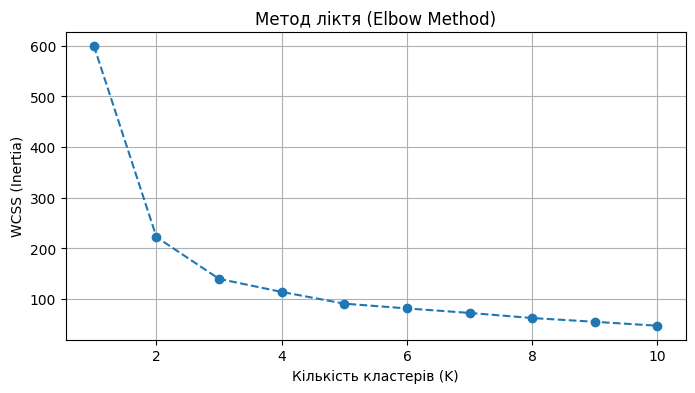

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_iris)

wcss = []
k_range = range(1, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, wcss, marker='o', linestyle='--')
plt.title('Метод ліктя (Elbow Method)')
plt.xlabel('Кількість кластерів (K)')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

K = 2, Silhouette Score = 0.5525
K = 3, Silhouette Score = 0.4594
K = 4, Silhouette Score = 0.4057
K = 5, Silhouette Score = 0.3755
K = 6, Silhouette Score = 0.3772
K = 7, Silhouette Score = 0.3628
K = 8, Silhouette Score = 0.3814
K = 9, Silhouette Score = 0.3749
K = 10, Silhouette Score = 0.3791


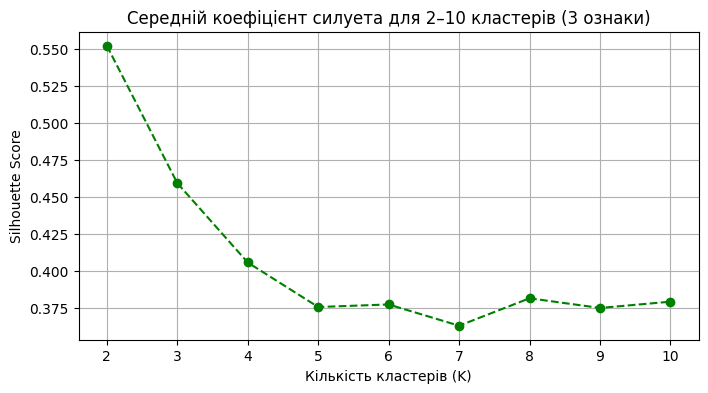

In [4]:
X_3d = X_scaled[:, :3]

silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_3d)
    score = silhouette_score(X_3d, cluster_labels)
    silhouette_scores.append(score)
    print(f"K = {k}, Silhouette Score = {score:.4f}")

# Побудова графіка
plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouette_scores, marker='o', color='green', linestyle='--')
plt.title('Середній коефіцієнт силуета для 2–10 кластерів (3 ознаки)')
plt.xlabel('Кількість кластерів (K)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

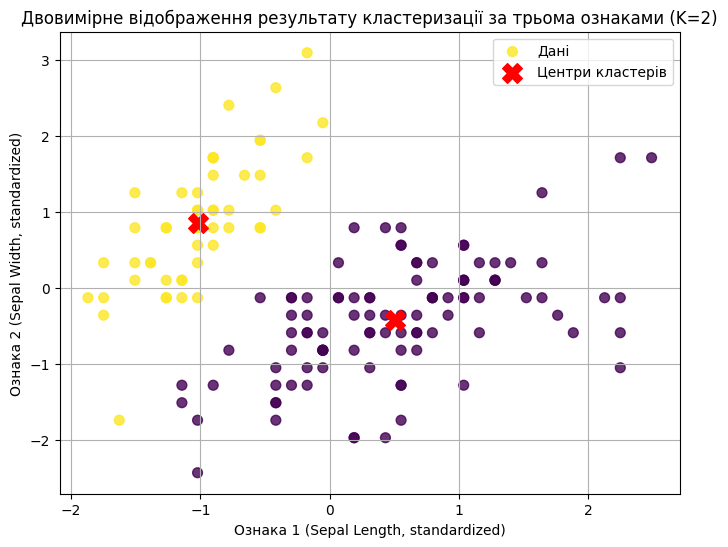

In [5]:
# Побудова K-Means для n_clusters=2
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans_final.fit_predict(X_3d)

# Координати центрів кластерів
centroids = kmeans_final.cluster_centers_

# Візуалізація перших двох ознак (на площині) та центрів кластерів
plt.figure(figsize=(8, 6))
plt.scatter(X_3d[:, 0], X_3d[:, 1], c=clusters, cmap='viridis', s=50, alpha=0.8, label='Дані')
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, label='Центри кластерів')

plt.title('Двовимірне відображення результату кластеризації за трьома ознаками (K=2)')
plt.xlabel('Ознака 1 (Sepal Length, standardized)')
plt.ylabel('Ознака 2 (Sepal Width, standardized)')
plt.legend()
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

Порівнюючи результати методу ліктя та методу силуетів, видно, що метод силуетів досягає свого максимуму при $K = 2$, що чітко вказує на оптимальний поділ даних на два основні кластери. На графіку методу ліктя перша чітко виражена точка згину («лікоть») також спостерігається при $K = 2$ (з можливим додатковим згином при $K = 3$).

Вибір двох кластерів пояснюється тим, що з точки зору структури даних Iris один клас (Iris setosa) є лінійно відокремлюваним від двох інших (Iris versicolor та Iris virginica), які частково перекриваються між собою. Отже, вибір $K = 2$ повністю збігається з отриманими графіками силуета та ліктя.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import io

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
uploaded = files.upload()

Saving Student_performance_data _.csv to Student_performance_data _.csv


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [9]:
df = pd.read_csv(io.BytesIO(uploaded[list(uploaded.keys())[0]]))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [14]:
print("--- Назви стовпців ---")
print(df.columns)
print()

--- Назви стовпців ---
Index(['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation',
       'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport',
       'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA',
       'GradeClass'],
      dtype='object')



**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [15]:
print("--- Структура таблиці ---")
df.info()
print()

--- Структура таблиці ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 K

**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [16]:
print("--- Пропущені значення ---")
print(df.isnull().sum())
print()

--- Пропущені значення ---
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64



**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [17]:
print("--- Кількість дублікатів ---")
print(f"Кількість дублікатів у датасеті: {df.duplicated().sum()}")

--- Кількість дублікатів ---
Кількість дублікатів у датасеті: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [18]:
print("--- Описова статистика ---")
print(df.describe())
print()

--- Описова статистика ---
         StudentID          Age       Gender    Ethnicity  ParentalEducation  \
count  2392.000000  2392.000000  2392.000000  2392.000000        2392.000000   
mean   2196.500000    16.468645     0.510870     0.877508           1.746237   
std     690.655244     1.123798     0.499986     1.028476           1.000411   
min    1001.000000    15.000000     0.000000     0.000000           0.000000   
25%    1598.750000    15.000000     0.000000     0.000000           1.000000   
50%    2196.500000    16.000000     1.000000     0.000000           2.000000   
75%    2794.250000    17.000000     1.000000     2.000000           2.000000   
max    3392.000000    18.000000     1.000000     3.000000           4.000000   

       StudyTimeWeekly     Absences     Tutoring  ParentalSupport  \
count      2392.000000  2392.000000  2392.000000      2392.000000   
mean          9.771992    14.541388     0.301421         2.122074   
std           5.652774     8.467417     0.458

**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [19]:
drop_cols = ['GradeClass']
if 'StudentID' in df.columns:
    drop_cols.append('StudentID')

X = df.drop(columns=drop_cols)
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [20]:
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf = RandomForestClassifier(random_state=42)

grid_rf = GridSearchCV(estimator=rf, param_grid=param_grid_rf, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X_train_scaled, y_train)

best_rf = grid_rf.best_estimator_
test_acc_rf = best_rf.score(X_test_scaled, y_test)

print("--- Результати Random Forest ---")
print(f"Найкращі параметри: {grid_rf.best_params_}")
print(f"Середня CV-точність (Best CV Accuracy): {grid_rf.best_score_:.4f}")
print(f"Тестова accuracy: {test_acc_rf:.4f}")

--- Результати Random Forest ---
Найкращі параметри: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV-точність (Best CV Accuracy): 0.9211
Тестова accuracy: 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [21]:
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l1', 'l2'],
    'solver': ['saga'],
    'max_iter': [500]
}

lr = LogisticRegression(random_state=42)

grid_lr = GridSearchCV(estimator=lr, param_grid=param_grid_lr, cv=5, scoring='accuracy', n_jobs=-1)
grid_lr.fit(X_train_scaled, y_train)

best_lr = grid_lr.best_estimator_
test_acc_lr = best_lr.score(X_test_scaled, y_test)

print("--- Результати Logistic Regression ---")
print(f"Найкращі параметри: {grid_lr.best_params_}")
print(f"Середня CV-точність (Best CV Accuracy): {grid_lr.best_score_:.4f}")
print(f"Тестова accuracy: {test_acc_lr:.4f}\n")

--- Результати Logistic Regression ---
Найкращі параметри: {'C': 0.1, 'max_iter': 500, 'penalty': 'l1', 'solver': 'saga'}
Середня CV-точність (Best CV Accuracy): 0.8024
Тестова accuracy: 0.8184



### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [23]:
param_grid_svm = {
    'C': [0.1, 1, 10],
    'kernel': ['rbf', 'linear', 'poly'],
    'gamma': ['scale', 'auto']
}

svm = SVC(random_state=42)

grid_svm = GridSearchCV(estimator=svm, param_grid=param_grid_svm, cv=5, scoring='accuracy', n_jobs=-1)
grid_svm.fit(X_train_scaled, y_train)

best_svm = grid_svm.best_estimator_
test_acc_svm = best_svm.score(X_test_scaled, y_test)

print("--- Результати Support Vector Machine ---")
print(f"Найкращі параметри: {grid_svm.best_params_}")
print(f"Середня CV-точність (Best CV Accuracy): {grid_svm.best_score_:.4f}")
print(f"Тестова accuracy: {test_acc_svm:.4f}")

--- Результати Support Vector Machine ---
Найкращі параметри: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV-точність (Best CV Accuracy): 0.8521
Тестова accuracy: 0.8580


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [25]:
models = {
    'Random Forest': (grid_rf.best_score_, test_acc_rf, best_rf),
    'Logistic Regression': (grid_lr.best_score_, test_acc_lr, best_lr),
    'SVM': (grid_svm.best_score_, test_acc_svm, best_svm)
}

df_results = pd.DataFrame({
    'Model': models.keys(),
    'CV Accuracy': [v[0] for v in models.values()],
    'Test Accuracy': [v[1] for v in models.values()]
})

print("--- Порівняння моделей класифікації ---")
print(df_results.to_string(index=False))
print()

best_model_name = max(models, key=lambda k: models[k][0])
best_model = models[best_model_name][2]

print(f"Найкраща модель за CV-точністю: {best_model_name}")
print("\nЗвіт classification_report для найкращої моделі на тестових даних:")

y_pred_best = best_model.predict(X_test_scaled)
print(classification_report(y_test, y_pred_best))

--- Порівняння моделей класифікації ---
              Model  CV Accuracy  Test Accuracy
      Random Forest     0.921071       0.910230
Logistic Regression     0.802411       0.818372
                SVM     0.852065       0.858038

Найкраща модель за CV-точністю: Random Forest

Звіт classification_report для найкращої моделі на тестових даних:
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

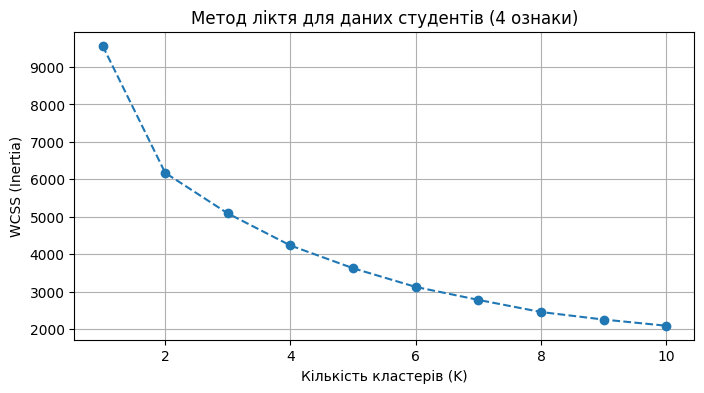

In [26]:
features = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_student_cluster = df[features]

scaler_student = StandardScaler()
X_student_scaled = scaler_student.fit_transform(X_student_cluster)

wcss_student = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_student_scaled)
    wcss_student.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, wcss_student, marker='o', linestyle='--')
plt.title('Метод ліктя для даних студентів (4 ознаки)')
plt.xlabel('Кількість кластерів (K)')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

K = 2, Silhouette Score = 0.3080
K = 3, Silhouette Score = 0.2702
K = 4, Silhouette Score = 0.2580
K = 5, Silhouette Score = 0.2645
K = 6, Silhouette Score = 0.2689
K = 7, Silhouette Score = 0.2692
K = 8, Silhouette Score = 0.2712
K = 9, Silhouette Score = 0.2732
K = 10, Silhouette Score = 0.2725


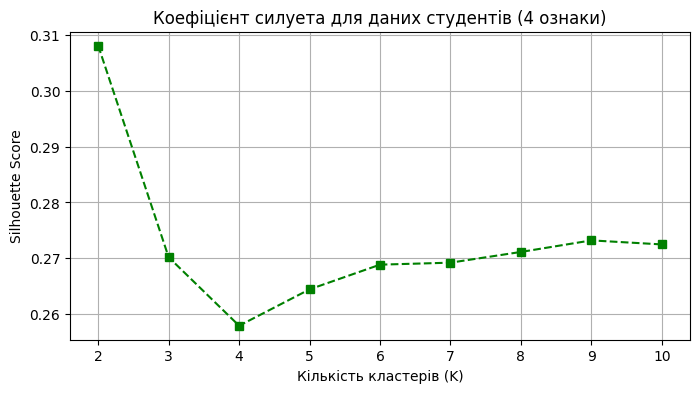

In [27]:
silhouette_scores_student = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_student_scaled)
    score = silhouette_score(X_student_scaled, cluster_labels)
    silhouette_scores_student.append(score)
    print(f"K = {k}, Silhouette Score = {score:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouette_scores_student, marker='s', color='green', linestyle='--')
plt.title('Коефіцієнт силуета для даних студентів (4 ознаки)')
plt.xlabel('Кількість кластерів (K)')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

Автоматично визначена точка ліктя (kneed): K = 3


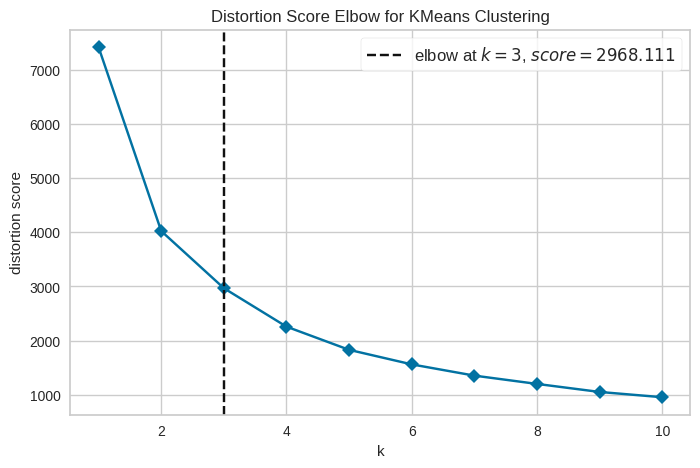

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [30]:
!pip install kneed yellowbrick

from yellowbrick.cluster import KElbowVisualizer
from sklearn.decomposition import PCA
from kneed import KneeLocator

drop_cols = ['GradeClass']
if 'StudentID' in df.columns:
    drop_cols.append('StudentID')

X_full = df.drop(columns=drop_cols)
X_full_scaled = scaler.fit_transform(X_full)

pca = PCA(n_components=2)
X_pca_full = pca.fit_transform(X_full_scaled)

wcss_pca = []
k_range_pca = range(1, 11)

for k in k_range_pca:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_pca_full)
    wcss_pca.append(km.inertia_)

kl = KneeLocator(range(1, 11), wcss_pca, curve="convex", direction="decreasing")
print(f"Автоматично визначена точка ліктя (kneed): K = {kl.elbow}")

plt.figure(figsize=(8, 5))
visualizer = KElbowVisualizer(KMeans(random_state=42, n_init=10), k=(1, 11), timings=False)
visualizer.fit(X_pca_full)
visualizer.show()

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [34]:
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [31]:
X_pca_input = df.drop(columns=['StudentID', 'GradeClass'], errors='ignore')

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [32]:
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca_input)

pca_model = PCA()
pca_model.fit(X_pca_scaled)
explained_variance_ratio = pca_model.explained_variance_ratio_

**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

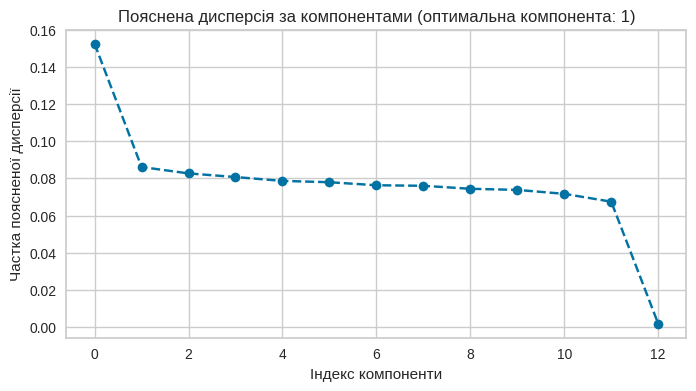

In [33]:
kl_pca = KneeLocator(
    range(len(explained_variance_ratio)),
    explained_variance_ratio,
    curve="convex",
    direction="decreasing"
)
elbow_idx = kl_pca.elbow

plt.figure(figsize=(8, 4))
plt.plot(range(len(explained_variance_ratio)), explained_variance_ratio, marker='o', linestyle='--')
plt.title(f'Пояснена дисперсія за компонентами (оптимальна компонента: {elbow_idx})')
plt.xlabel('Індекс компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

Знайдена кількість компонент: 2
Фактична частка поясненої дисперсії: 0.2386 (23.86%)


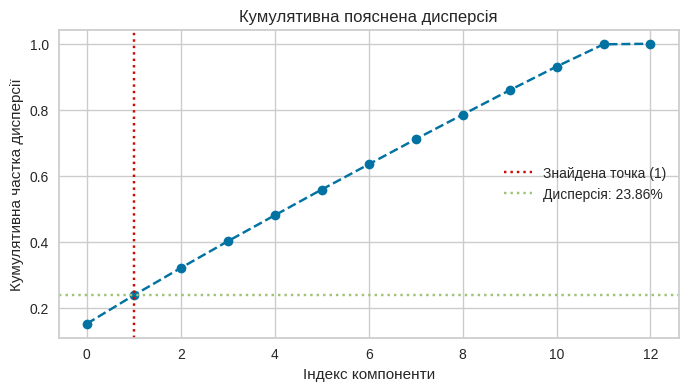

In [35]:
cum_variance = np.cumsum(explained_variance_ratio)

n_selected_components = elbow_idx + 1
actual_variance_share = cum_variance[elbow_idx]

print(f"Знайдена кількість компонент: {n_selected_components}")
print(f"Фактична частка поясненої дисперсії: {actual_variance_share:.4f} ({actual_variance_share * 100:.2f}%)")

plt.figure(figsize=(8, 4))
plt.plot(range(len(cum_variance)), cum_variance, marker='o', linestyle='--')
plt.axvline(x=elbow_idx, color='r', linestyle=':', label=f'Знайдена точка ({elbow_idx})')
plt.axhline(y=actual_variance_share, color='g', linestyle=':', label=f'Дисперсія: {actual_variance_share:.2%}')

plt.title('Кумулятивна пояснена дисперсія')
plt.xlabel('Індекс компоненти')
plt.ylabel('Кумулятивна частка дисперсії')
plt.legend()
plt.grid(True)
plt.show()

pca_final = PCA(n_components=n_selected_components)
X_pca_transformed = pca_final.fit_transform(X_pca_scaled)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [36]:
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

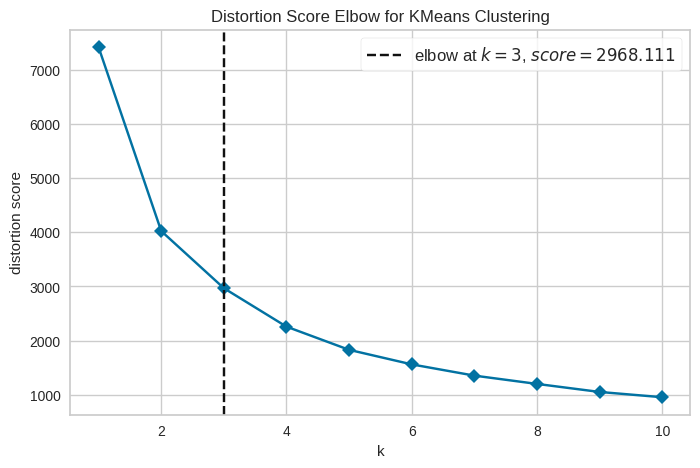

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [37]:
plt.figure(figsize=(8, 5))
visualizer = KElbowVisualizer(KMeans(random_state=42, n_init=10), k=(1, 11), timings=False)
visualizer.fit(X_pca_transformed)
visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

У ході виконання роботи ми порівняли різні підходи до визначення кількості кластерів та дослідили класифікацію й кластеризацію на даних. Для набору Iris метод силуетів досяг максимуму при $K = 2$, що повністю збігається з точкою згину на графіку методу ліктя та пояснюється чітким відокремленням класу Iris setosa від інших. На даних студентів метод силуетів також показав найкращий результат для 2 кластерів, тоді як після застосування PCA автоматичний аналіз за допомогою KElbowVisualizer чітко визначив точку ліктя при $K = 3$.   Головна відмінність між класифікацією та кластеризацією полягає в тому, що класифікація є навчанням з учителем і передбачає цільову змінну GradeClass, тоді як кластеризація групує студентів без застосування цієї мітки — виключно на основі подібності їхніх числових характеристик. За допомогою KneeLocator для PCA було визначено 2 головні компоненти, які пояснюють 23.86% сукупної дисперсії даних, що вказує на складну та слабкокорельовану структуру ознак у цьому датасеті.  